## Performing EDA process

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "../dataset/cleaned_data_2/sale_data_cleaned.csv",
    parse_dates=["Date"],
    index_col="Date",
)

In [3]:
df

,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,72.468262,72.528582,71.223259,71.476600,135480400.0
2020-01-03,71.763718,72.523746,71.539330,71.696160,146322800.0
2020-01-06,72.335564,72.374169,70.634547,70.885479,118387200.0
2020-01-07,71.995338,72.600945,71.775773,72.345189,108872000.0
2020-01-08,73.153488,73.455087,71.698574,71.698574,132079200.0
...,...,...,...,...,...
2024-12-24,257.037506,257.047440,254.140589,254.339701,23234700.0
2024-12-26,257.853790,258.928945,256.470064,257.027541,27237100.0
2024-12-27,254.439240,257.535253,251.920632,256.669145,42355300.0


In [4]:
df.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')

In [5]:
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,72.468262,72.528582,71.223259,71.476600,135480400.0
2020-01-03,71.763718,72.523746,71.539330,71.696160,146322800.0
2020-01-06,72.335564,72.374169,70.634547,70.885479,118387200.0
2020-01-07,71.995338,72.600945,71.775773,72.345189,108872000.0
2020-01-08,73.153488,73.455087,71.698574,71.698574,132079200.0


In [6]:
df.tail()

,Close,High,Low,Open,Volume
Date,,,,,
2024-12-24,257.037506,257.047440,254.140589,254.339701,23234700.0
2024-12-26,257.853790,258.928945,256.470064,257.027541,27237100.0
2024-12-27,254.439240,257.535253,251.920632,256.669145,42355300.0
2024-12-30,251.064514,252.358664,249.621046,251.094378,35557500.0
2024-12-31,249.292511,252.139635,248.306963,251.303420,39480700.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2020-01-02 to 2024-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1258 non-null   float64
 1   High    1258 non-null   float64
 2   Low     1258 non-null   float64
 3   Open    1258 non-null   float64
 4   Volume  1258 non-null   float64
dtypes: float64(5)
memory usage: 59.0 KB


In [8]:
df.describe()

,Close,High,Low,Open,Volume
count,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03
mean,151.659031,153.183638,149.958963,151.504428,9.057103e+07
std,41.929756,42.070381,41.706646,41.873458,5.324438e+07
min,54.264324,55.263174,51.420146,55.161597,2.323470e+07
25%,126.513720,127.633765,124.509429,125.957965,5.546825e+07
50%,150.247246,151.991617,148.312202,150.067184,7.628335e+07
75%,176.228836,177.782107,174.661147,176.034688,1.077425e+08
max,257.853790,258.928945,256.470064,257.027541,4.265100e+08


In [9]:
## to check full data range , confirms chronological order
print(df.index.min())
print(df.index.max())

df.index.is_monotonic_increasing

2020-01-02 00:00:00
2024-12-31 00:00:00


True

In [10]:
## to find missing days 
all_days = pd.date_range(df.index.min() , df.index.max() , freq = 'B')   #finds all day from mon to fri by min -> max
missing_days = all_days.difference(df.index)                             #it checks dates present in all_days but not in index

len(missing_days)

46

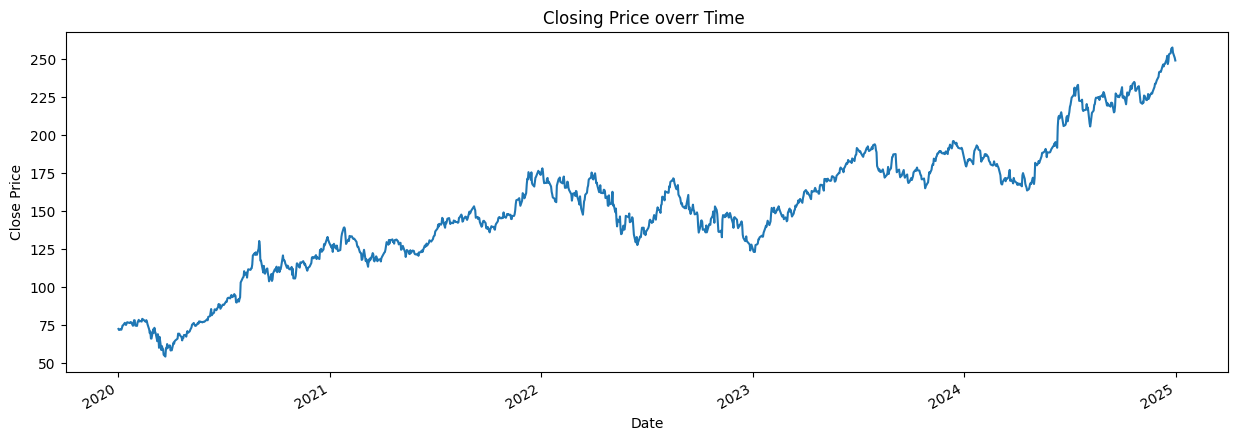

In [11]:
## see closing price trend

df['Close'].plot(figsize=(15 , 5),title = "Closing Price overr Time ")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

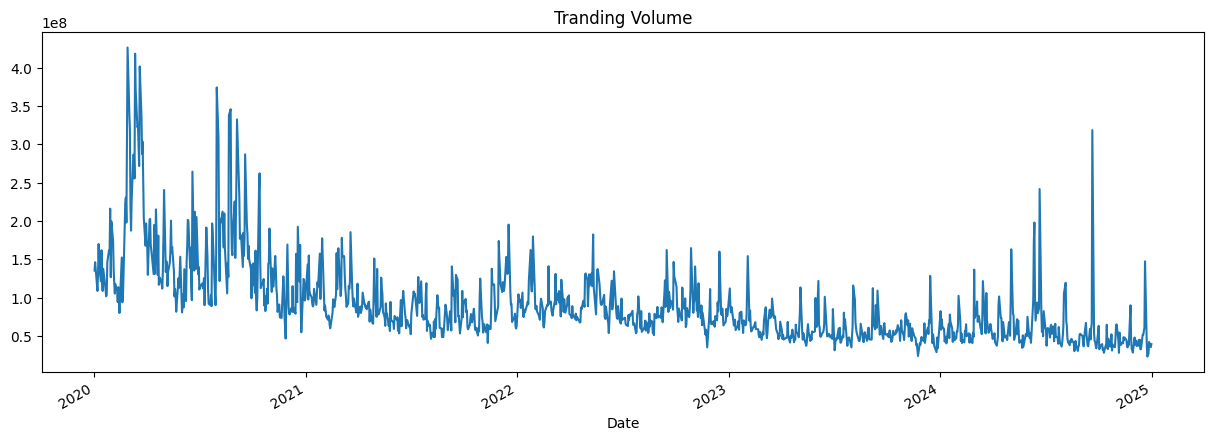

In [12]:
## Volume analysis (conviction)

df["Volume"].plot(figsize=(15, 5), title="Tranding Volume")
plt.show()

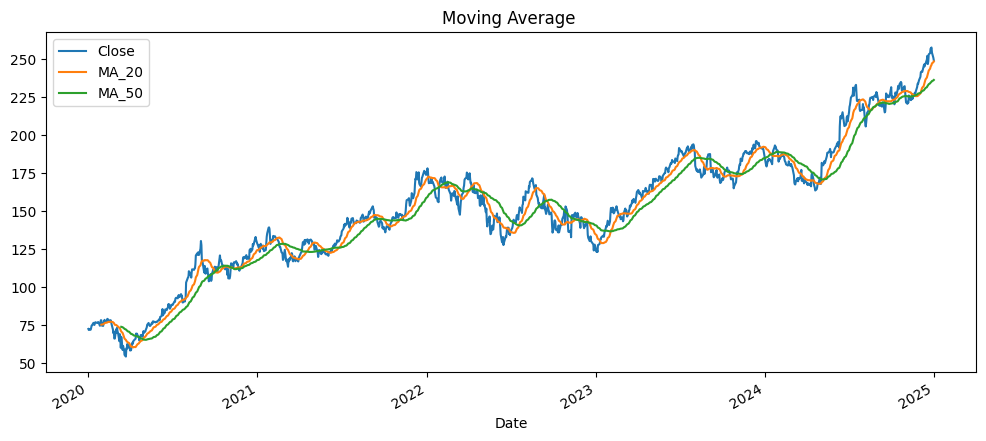

In [13]:
## MOving Average(MA) (trend smoothing)  removes the noice
## it usually says that : above MA -> may be bullish trend       below MA -> may be bearish trend

df["MA_20"] = df["Close"].rolling(20).mean()
df["MA_50"] = df["Close"].rolling(50).mean()

df[["Close", "MA_20", "MA_50"]].plot(figsize=(12, 5), title="Moving Average ")
plt.show()

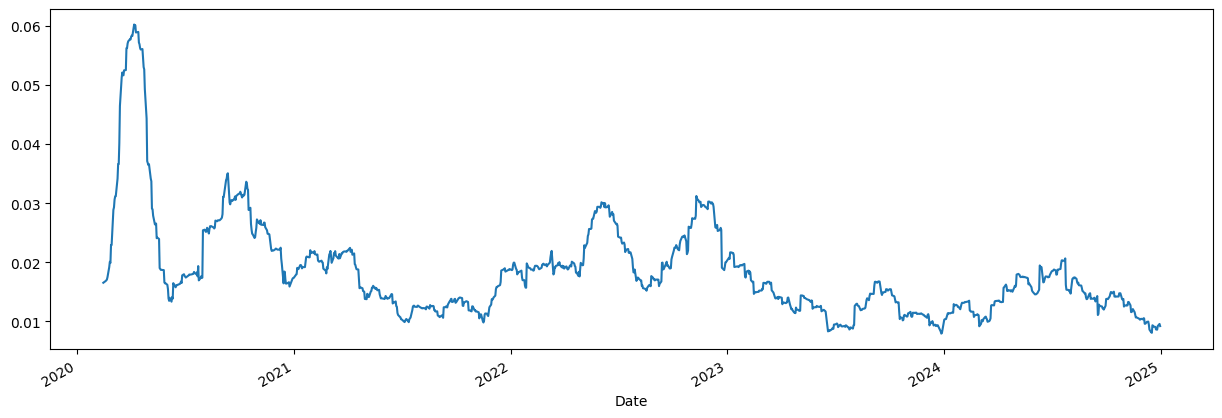

In [14]:
## rolling is used to check : How unstable the stock is over time , it tell about that not every time stocks are risky 

df["Close"].pct_change().rolling(30).std().plot(figsize=(15, 5))
plt.show()

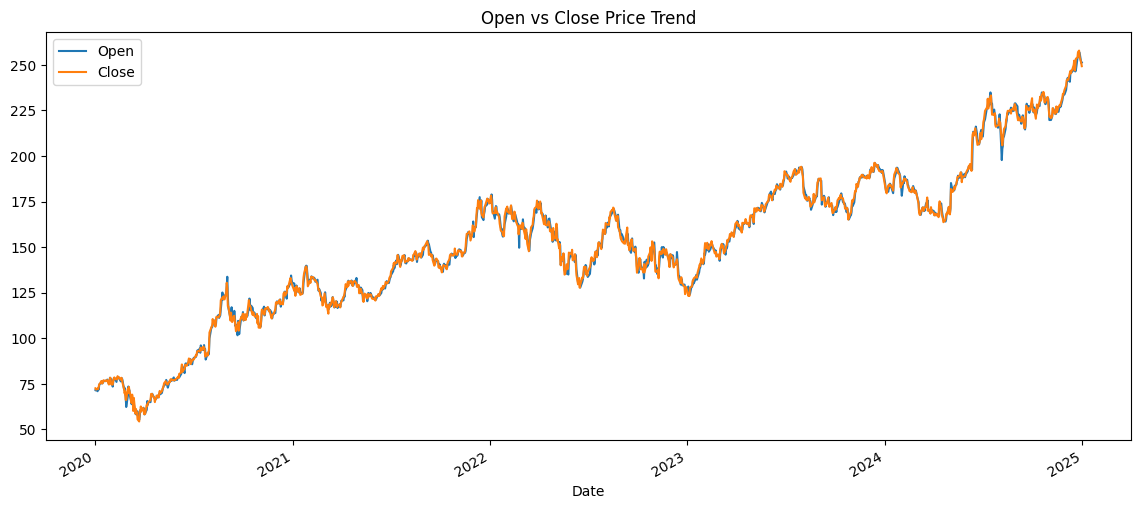

In [15]:
## Open Vs Close Price Trend Analysis

df[["Open", "Close"]].plot(figsize=(14, 6))
plt.title("Open vs Close Price Trend")
plt.show()


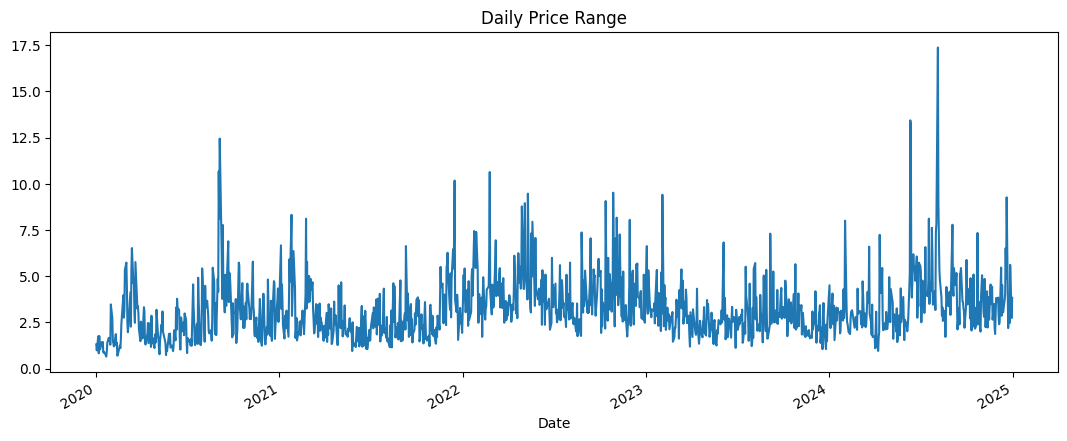

In [16]:
## see trend of High- low i.e price range :
## Takes the highest price of the day
# Takes the lowest price of the day
# Subtracts Low from High
# Stores the result in a new column called Daily_Range


df["Daily_Range"] = df["High"] - df["Low"]

df["Daily_Range"].plot(figsize=(13, 5), title="Daily Price Range")
plt.show()

## mostly used for intraday volatility not for investment

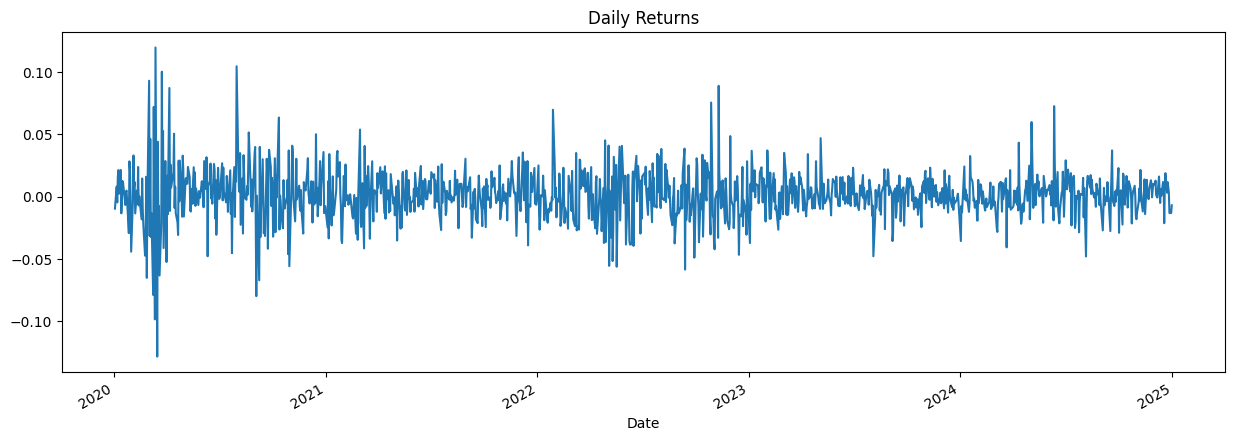

In [17]:
## to see trend in daily return : "How much did the price change today relative to yesterday?"
# “If I bought yesterday and sold today, how much did I gain or lose in percentage?”   if spike high -> profit
#                                                                                      & if spike is low -> loss
# pct_change() calculates :
# Daily_Return = (Today_Close - Yesterday_Close) / Yesterday_Close

# dropna is used coz 1st day has no previous day

df["Daily_Return"] = df["Close"].pct_change()

df["Daily_Return"].dropna().plot(figsize=(15,5) , title="Daily Returns")
plt.show()

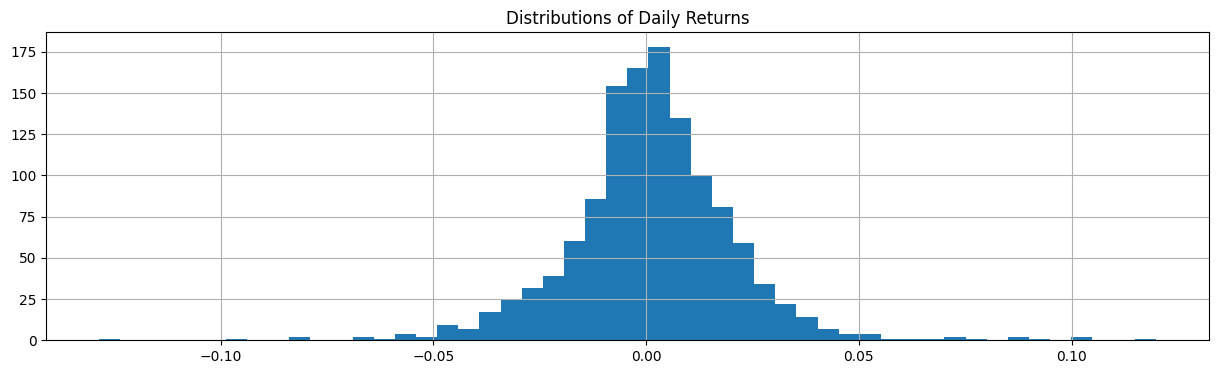

In [18]:
# using histogram for returns distribution

df["Daily_Return"].dropna().hist(bins=50 , figsize=(15, 4))
plt.title("Distributions of Daily Returns")
plt.show()

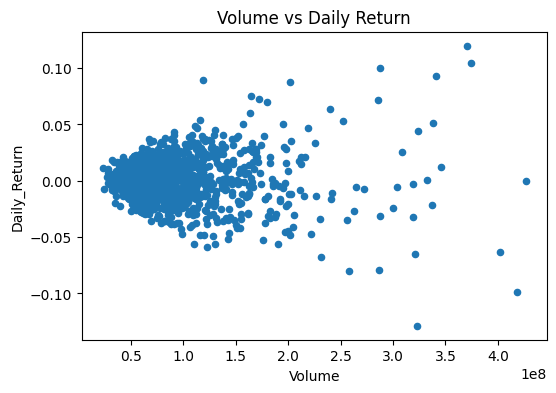

In [19]:
## Price Vs Volume relationship

df.plot.scatter(
    x="Volume", y="Daily_Return", figsize=(6, 4), title="Volume vs Daily Return"
)
plt.show()

In [20]:
##Correlation matrix (sanity check) : catches data errors.

df[["Open", "High", "Low", "Close", "Volume"]].corr()

,Open,High,Low,Close,Volume
Open,1.000000,0.999400,0.999401,0.998661,-0.637840
High,0.999400,1.000000,0.999260,0.999398,-0.629894
Low,0.999401,0.999260,1.000000,0.999395,-0.646038
Close,0.998661,0.999398,0.999395,1.000000,-0.638245
Volume,-0.637840,-0.629894,-0.646038,-0.638245,1.000000


In [21]:
df["Daily_Return"].abs().sort_values(ascending=False).head(10)

Date
2020-03-16    0.128647
2020-03-13    0.119808
2020-07-31    0.104689
2020-03-24    0.100326
2020-03-12    0.098755
2020-03-02    0.093101
2022-11-10    0.088975
2020-04-06    0.087237
2020-09-03    0.080061
2020-03-09    0.079092
Name: Daily_Return, dtype: float64

In [22]:
df.to_csv(r"..\dataset/processed_data_3/sales_data_eda_ready.csv")

In [23]:
###for next to load dataset into other file :
# df_ml = pd.read_csv(
#     "dataset/processed/sales_data_eda_ready.csv", parse_dates=["Date"], index_col="Date"
# )

In [24]:
df

,Close,High,Low,Open,Volume,MA_20,MA_50,Daily_Range,Daily_Return
Date,,,,,,,,,
2020-01-02,72.468262,72.528582,71.223259,71.476600,135480400.0,NaN,NaN,1.305322,NaN
2020-01-03,71.763718,72.523746,71.539330,71.696160,146322800.0,NaN,NaN,0.984417,-0.009722
2020-01-06,72.335564,72.374169,70.634547,70.885479,118387200.0,NaN,NaN,1.739622,0.007968
2020-01-07,71.995338,72.600945,71.775773,72.345189,108872000.0,NaN,NaN,0.825171,-0.004703
2020-01-08,73.153488,73.455087,71.698574,71.698574,132079200.0,NaN,NaN,1.756513,0.016086
...,...,...,...,...,...,...,...,...,...
2024-12-24,257.037506,257.047440,254.140589,254.339701,23234700.0,245.184590,234.761247,2.906851,0.011478
2024-12-26,257.853790,258.928945,256.470064,257.027541,27237100.0,246.377197,235.267498,2.458880,0.003176
2024-12-27,254.439240,257.535253,251.920632,256.669145,42355300.0,247.405546,235.746625,5.614621,-0.013242
